In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import sklearn
from sklearn.linear_model import LinearRegression
import statsmodels.api as sm
from scipy import stats
import numpy as np
from scipy.optimize import minimize
from tqdm import tqdm
from sklearn.metrics import r2_score
from datetime import datetime, timedelta
import seaborn as sns
import re

# Make sure that all columns are visible when a dataframe is printed
pd.set_option('display.max_columns', None)

In [2]:
# Read the raw COVID-radar data
df_radar = pd.read_csv("data/COVID_radar_data/CRdataShared.csv")

# Make sure the date column is a datetime object
df_radar['date'] = pd.to_datetime(df_radar['date'], format='%d%b%Y')

df_radar.head()

,gender,age,profession,contact,cough,sorethroat,fever,shortofbreath,bowelsymptoms,chestsymptoms,eyesymptoms,lossofsmell,fatigue,headache,vaccine,outhousework,outofhouse,numberpersons5m,numbervisitors,numberpersons150cm,numberpersons150cmspoken,mask,public,holiday,brainfog,depressed,date,fatigueExtreme,sport,ID,positivetest,numbertimescovid,firstpositivetest,dayssurroundingpositivetest,everpositive,negativetest,numbernegativetest,firstnegativetest,dayssurroundingnegativetest,evernegativetest,evercovidinapp,evercovidoutapp
0,f,06-11,NaN,0,1,0,0,0,0,0,0.0,0,NaN,NaN,NaN,0,0.0,1,2,0,0,NaN,NaN,NaN,NaN,NaN,2020-04-05,NaN,NaN,1,0,0,0,NaN,0,0,0,0,NaN,0,NaN,0
1,f,06-11,NaN,0,1,0,0,0,0,0,0.0,0,NaN,NaN,NaN,0,5.0,0,0,0,0,NaN,NaN,NaN,NaN,NaN,2020-04-06,NaN,NaN,1,0,0,0,NaN,0,0,0,0,NaN,0,NaN,0
2,f,06-11,NaN,0,0,0,0,0,0,0,0.0,0,NaN,NaN,NaN,0,5.0,1,0,5,0,NaN,NaN,NaN,NaN,NaN,2020-04-08,NaN,NaN,1,0,0,0,NaN,0,0,0,0,NaN,0,NaN,0
3,f,06-11,NaN,0,0,0,0,0,0,0,0.0,0,NaN,NaN,NaN,0,0.0,0,0,0,0,NaN,NaN,NaN,NaN,NaN,2020-04-15,NaN,NaN,1,0,0,0,NaN,0,0,0,0,NaN,0,NaN,0
4,f,06-11,NaN,0,0,0,0,0,0,0,0.0,0,NaN,NaN,NaN,0,0.0,0,0,0,0,NaN,NaN,NaN,NaN,NaN,2020-05-14,NaN,NaN,1,0,0,0,NaN,0,0,0,0,NaN,0,NaN,0


In [3]:
# Get unique IDs and dates
unique_ids = df_radar['ID'].unique()
unique_dates = df_radar['date'].unique()

# For all dates, calculate which dates should be in the exposure period if that date is taken as the test date
date_ranges = {
    t0: [(t0 + pd.Timedelta(days=t)) for t in range(-35, 6)] for t0 in unique_dates
}

# Check if the date ranges are correct
# The result is a dictionary with each test date as the key and the dates in the exposure period the values (in a list)
#date_ranges

In [4]:
results = []

# Filter df_radar to only include rows with a test result
df_radar_with_tests = df_radar[(df_radar['positivetest'] == 1) | (df_radar['negativetest'] == 1)]

# Get all dates and IDs from persons who tested
unique_dates = df_radar['date'].unique()
test_ids = df_radar_with_tests['ID'].unique()

# Batch processing was used such that a progress bar could be used
batch_size = 5000

# Loop over all IDs that performed a test in batches
for i in tqdm(range(0, len(test_ids), batch_size)):
    
    # Get the correct IDs and extract all surveys for those IDS
    batch_ids = list(test_ids)[i:i + batch_size]
    batch_data = df_radar[df_radar['ID'].isin(batch_ids)]

    # For each t0 (test) date
    for t0_date in unique_dates:
        
        # Get t1-T11 date range as made in the previous cell (exposure period)
        t1_t11_dates = date_ranges.get(t0_date, [])

        # Get the corresponding surveys that are in the exposure periods
        t1_t11_data = batch_data[batch_data['date'].isin(t1_t11_dates)]

        # Create 11 columns for numbervisitors and numberpersons150cm and fill them with the correct values
        t1_t11_summary = t1_t11_data.pivot_table(
            index="ID",
            columns="date",
            values=["numbervisitors", "numberpersons150cm"]
        )
        t1_t11_summary.columns = [
            f"{col[0]}_T{(col[1] - t0_date).days}" for col in t1_t11_summary.columns
        ]
        t1_t11_summary = t1_t11_summary.reset_index()

        # Add T0_date column
        t1_t11_summary['T0_date'] = t0_date

        # Get all tests performed at the current t0 date
        test_subset = df_radar_with_tests[df_radar_with_tests['date'] == t0_date]
        test_subset = test_subset[['ID', 'positivetest', 'negativetest']].drop_duplicates()
        
        # Merge test results with the correct behavioral data
        merged_summary = test_subset.merge(t1_t11_summary, on='ID', how='left')

        # Append the results for this t0 date
        results.append(merged_summary)

# Concatenate the results of all t0 dates
df_final = pd.concat(results, ignore_index=True)

df_merged2 = pd.merge(df_final, df_radar[['ID', 'date', 'age', 'profession', 'positivetest', 'negativetest']], 
                     left_on=['ID', 'T0_date'], right_on=['ID', 'date'], how='inner')

df_merged2 = df_merged2.drop(columns=['positivetest_y', 'negativetest_y'])

df_merged2.rename(columns={'positivetest_x': 'positivetest', 'negativetest_x': 'negativetest'}, inplace=True)

df_merged2

100%|████████████████████████████████████████████████████████████████████████████████████| 5/5 [02:05<00:00, 25.12s/it]


,ID,positivetest,negativetest,numberpersons150cm_T-2,numberpersons150cm_T-1,numberpersons150cm_T0,numberpersons150cm_T1,numberpersons150cm_T2,numberpersons150cm_T3,numberpersons150cm_T4,numberpersons150cm_T5,numbervisitors_T-2,numbervisitors_T-1,numbervisitors_T0,numbervisitors_T1,numbervisitors_T2,numbervisitors_T3,numbervisitors_T4,numbervisitors_T5,T0_date,numberpersons150cm_T-3,numbervisitors_T-3,numberpersons150cm_T-5,numberpersons150cm_T-4,numbervisitors_T-5,numbervisitors_T-4,numberpersons150cm_T-12,numberpersons150cm_T-11,numberpersons150cm_T-10,numberpersons150cm_T-9,numberpersons150cm_T-8,numberpersons150cm_T-7,numberpersons150cm_T-6,numbervisitors_T-12,numbervisitors_T-11,numbervisitors_T-10,numbervisitors_T-9,numbervisitors_T-8,numbervisitors_T-7,numbervisitors_T-6,numberpersons150cm_T-35,numberpersons150cm_T-34,numberpersons150cm_T-33,numberpersons150cm_T-32,numberpersons150cm_T-31,numberpersons150cm_T-30,numberpersons150cm_T-29,numberpersons150cm_T-28,numberpersons150cm_T-27,numberpersons150cm_T-26,numberpersons150cm_T-25,numberpersons150cm_T-24,numberpersons150cm_T-23,numberpersons150cm_T-22,numberpersons150cm_T-21,numberpersons150cm_T-20,numberpersons150cm_T-19,numberpersons150cm_T-18,numberpersons150cm_T-17,numberpersons150cm_T-16,numberpersons150cm_T-15,numberpersons150cm_T-14,numberpersons150cm_T-13,numbervisitors_T-35,numbervisitors_T-34,numbervisitors_T-33,numbervisitors_T-32,numbervisitors_T-31,numbervisitors_T-30,numbervisitors_T-29,numbervisitors_T-28,numbervisitors_T-27,numbervisitors_T-26,numbervisitors_T-25,numbervisitors_T-24,numbervisitors_T-23,numbervisitors_T-22,numbervisitors_T-21,numbervisitors_T-20,numbervisitors_T-19,numbervisitors_T-18,numbervisitors_T-17,numbervisitors_T-16,numbervisitors_T-15,numbervisitors_T-14,numbervisitors_T-13,date,age,profession
0,48475,1,0,0.0,0.0,1.0,1.0,NaN,0.0,NaN,1.0,0.0,0.0,1.0,1.0,NaN,0.0,NaN,0.0,2020-04-05,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,2020-04-05,19-29,NaN
1,20259,1,0,NaN,0.0,0.0,NaN,0.0,NaN,NaN,NaN,NaN,0.0,0.0,NaN,0.0,NaN,NaN,NaN,2020-04-06,0.0,0.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,2020-04-06,19-29,NaN
2,8072,1,0,NaN,0.0,0.0,NaN,NaN,NaN,NaN,2.0,NaN,0.0,2.0,NaN,NaN,NaN,NaN,2.0,2020-04-08,NaN,NaN,0.0,NaN,0.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,2020-04-08,40-49,NaN
3,37377,1,0,NaN,NaN,0.0,NaN,0.0,NaN,NaN,0.0,NaN,NaN,0.0,NaN,0.0,NaN,NaN,1.0,2020-04-08,0.0,0.0,NaN,0.0,NaN,0.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,2020-04-08,50-59,NaN
4,46069,1,0,0.0,0.0,0.0,0.0,NaN,0.0,NaN,NaN,0.0,0.0,0.0,0.0,NaN,0.0,NaN,NaN,2020-04-08,0.0,0.0,0.0,NaN,1.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,2020-04-08,50-59,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,.

In [5]:
df_frame = df_merged2.copy()

# Filter for the rows where a negative test was reported
negative_tests = df_radar[df_radar['negativetest'] == 1]

# Find the earliest date where a negative test was reported
first_negative_test_date = negative_tests['date'].min()

# Print the earliest date for the negative test
print(f"The first negative test was reported on: {first_negative_test_date}")

# Only select tests occuring after this date from the original data
df_frame = df_frame[df_frame['T0_date'] >= pd.Timestamp("2021-01-01")]

The first negative test was reported on: 2021-01-15 00:00:00


Compare the average behavior of all persons who tested positive from 2021-01-15 on with the average behavior

In [7]:
df_postest = df_frame[
    (df_frame["positivetest"] == 1) & 
    (df_frame["T0_date"] >= pd.Timestamp("2021-01-15"))
]

df_negtest = df_frame[
    (df_frame["negativetest"] == 1) & 
    (df_frame["T0_date"] >= pd.Timestamp("2021-01-15"))
]

# Define column names
persons_columns = sorted(
    [col for col in df_postest.columns if col.startswith("numberpersons150cm_T")],
    key=lambda x: int(x.split("_T")[-1])
)
visitors_columns = sorted(
    [col for col in df_postest.columns if col.startswith("numbervisitors_T")],
    key=lambda x: int(x.split("_T")[-1])
)

# December 11th, as we are taking 35 days before 15-jan-2021 (First date that tests could be reported)
df_frame_radar = df_radar[df_radar['date'] >= pd.Timestamp("2020-12-11")]

# Compute column-wise means
mean_persons = df_frame_radar["numberpersons150cm"].mean(skipna=True)
mean_visitors = df_frame_radar["numbervisitors"].mean(skipna=True)

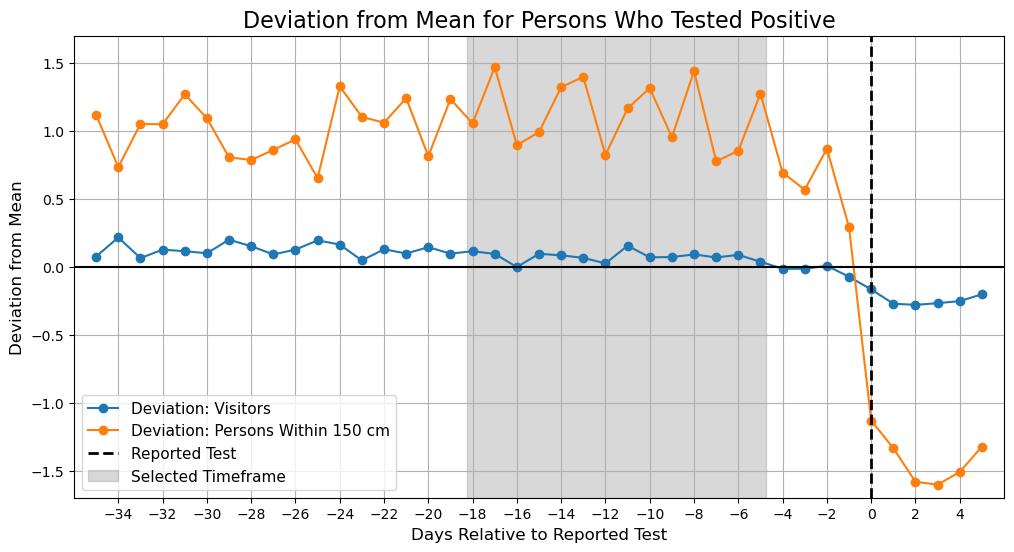

In [8]:
# Extract relative time offsets from column names like 'numberpersons150cm_T-35'
time_offsets = [int(re.search(r"_T(-?\d+)", col).group(1)) for col in persons_columns]

# Sort columns and offsets together to maintain correct order
sorted_columns_with_offsets = sorted(zip(time_offsets, persons_columns), key=lambda x: x[0])
sorted_offsets, sorted_persons_columns = zip(*sorted_columns_with_offsets)

# Do the same for visitors
time_offsets_visitors = [int(re.search(r"_T(-?\d+)", col).group(1)) for col in visitors_columns]
sorted_columns_with_offsets_visitors = sorted(zip(time_offsets_visitors, visitors_columns), key=lambda x: x[0])
_, sorted_visitors_columns = zip(*sorted_columns_with_offsets_visitors)

# Recalculate deviations with sorted columns
diff_persons = df_postest[list(sorted_persons_columns)] - mean_persons
diff_visitors = df_postest[list(sorted_visitors_columns)] - mean_visitors

# Mean deviations
mean_diff_persons = diff_persons.mean(skipna=True)
mean_diff_visitors = diff_visitors.mean(skipna=True)

# Plot using correct time offsets
plt.figure(figsize=(12, 6))

plt.plot(sorted_offsets, mean_diff_visitors, marker='o', linestyle='-', label="Deviation: Visitors")
plt.plot(sorted_offsets, mean_diff_persons, marker='o', linestyle='-', label="Deviation: Persons Within 150 cm")

plt.xlabel("Days Relative to Reported Test", size=12)
plt.ylabel("Deviation from Mean", size=12)
plt.title("Deviation from Mean for Persons Who Tested Positive", size=16)

# Show every second tick (e.g., -35, -33, -31, ..., 3, 5)
every_second_tick = [x for i, x in enumerate(sorted_offsets) if i % 2 != 0]
plt.xticks(every_second_tick)

plt.axhline(0, color='black', linestyle='-')
plt.axvline(x=0, color='black', linestyle='--', linewidth=2, label="Reported Test")

plt.xlim(-36, 6)
plt.ylim(-1.7, 1.7)

# For example, highlight T-18 to T-5 as your "selected timeframe"
plt.axvspan(-18.25, -4.75, color='gray', alpha=0.3, label="Selected Timeframe")

plt.legend(fontsize=11)
plt.grid()
plt.savefig("images/timeframe_selection.png", dpi=600, bbox_inches='tight')
plt.show()

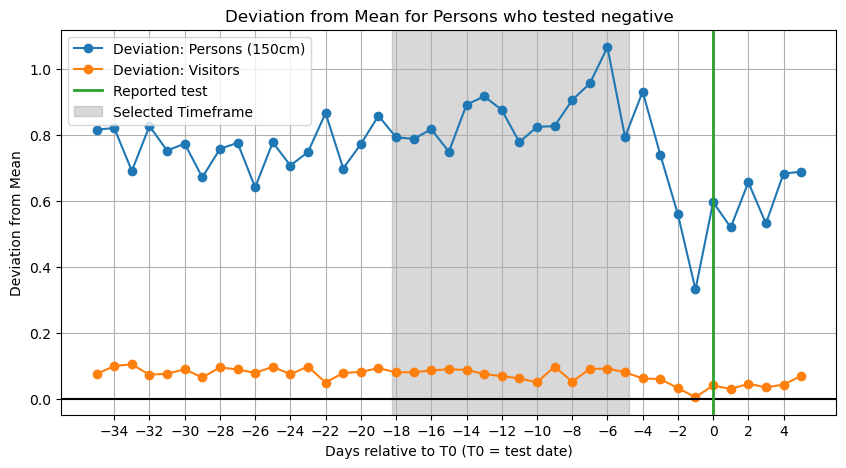

In [15]:
# Extract relative time offsets from column names like 'numberpersons150cm_T-35'
time_offsets = [int(re.search(r"_T(-?\d+)", col).group(1)) for col in persons_columns]

# Sort columns and offsets together to maintain correct order
sorted_columns_with_offsets = sorted(zip(time_offsets, persons_columns), key=lambda x: x[0])
sorted_offsets, sorted_persons_columns = zip(*sorted_columns_with_offsets)

# Do the same for visitors
time_offsets_visitors = [int(re.search(r"_T(-?\d+)", col).group(1)) for col in visitors_columns]
sorted_columns_with_offsets_visitors = sorted(zip(time_offsets_visitors, visitors_columns), key=lambda x: x[0])
_, sorted_visitors_columns = zip(*sorted_columns_with_offsets_visitors)

# Recalculate deviations with sorted columns
diff_persons = df_negtest[list(sorted_persons_columns)] - mean_persons
diff_visitors = df_negtest[list(sorted_visitors_columns)] - mean_visitors

# Mean deviations
mean_diff_persons = diff_persons.mean(skipna=True)
mean_diff_visitors = diff_visitors.mean(skipna=True)

# Plot using correct time offsets
plt.figure(figsize=(10, 5))

plt.plot(sorted_offsets, mean_diff_persons, marker='o', linestyle='-', label="Deviation: Persons (150cm)")
plt.plot(sorted_offsets, mean_diff_visitors, marker='o', linestyle='-', label="Deviation: Visitors")

plt.xlabel("Days relative to T0 (T0 = test date)")
plt.ylabel("Deviation from Mean")
plt.title("Deviation from Mean for Persons who tested negative")
# Show every second tick (e.g., -35, -33, -31, ..., 3, 5)
every_second_tick = [x for i, x in enumerate(sorted_offsets) if i % 2 != 0]
plt.xticks(every_second_tick)

plt.axhline(0, color='black', linestyle='-')
plt.axvline(x=0, color='tab:green', linestyle='-', linewidth=2, label="Reported test")  # T0

# For example, highlight T-18 to T-5 as your "selected timeframe"
plt.axvspan(-18.25, -4.75, color='gray', alpha=0.3, label="Selected Timeframe")

plt.legend()
plt.grid()
plt.show()

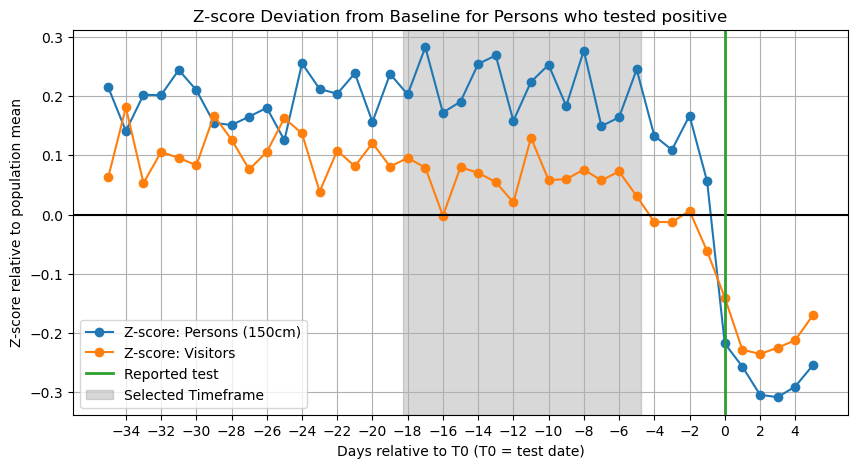

In [17]:
import re

# Extract relative time offsets from column names like 'numberpersons150cm_T-35'
time_offsets = [int(re.search(r"_T(-?\d+)", col).group(1)) for col in persons_columns]

# Sort columns and offsets together
sorted_columns_with_offsets = sorted(zip(time_offsets, persons_columns), key=lambda x: x[0])
sorted_offsets, sorted_persons_columns = zip(*sorted_columns_with_offsets)

# Do the same for visitors
time_offsets_visitors = [int(re.search(r"_T(-?\d+)", col).group(1)) for col in visitors_columns]
sorted_columns_with_offsets_visitors = sorted(zip(time_offsets_visitors, visitors_columns), key=lambda x: x[0])
_, sorted_visitors_columns = zip(*sorted_columns_with_offsets_visitors)

# Compute mean and std from the baseline (not positive cases!)
mean_persons_baseline = df_frame_radar["numberpersons150cm"].mean(skipna=True)
std_persons_baseline = df_frame_radar["numberpersons150cm"].std(skipna=True)

mean_visitors_baseline = df_frame_radar["numbervisitors"].mean(skipna=True)
std_visitors_baseline = df_frame_radar["numbervisitors"].std(skipna=True)

# Compute z-scores for positive-test group
z_persons = (df_postest[list(sorted_persons_columns)] - mean_persons_baseline) / std_persons_baseline
z_visitors = (df_postest[list(sorted_visitors_columns)] - mean_visitors_baseline) / std_visitors_baseline

# Mean z-score for each day (column)
mean_z_persons = z_persons.mean(skipna=True)
mean_z_visitors = z_visitors.mean(skipna=True)

# Plot
plt.figure(figsize=(10, 5))

plt.plot(sorted_offsets, mean_z_persons, marker='o', linestyle='-', label="Z-score: Persons (150cm)")
plt.plot(sorted_offsets, mean_z_visitors, marker='o', linestyle='-', label="Z-score: Visitors")

plt.xlabel("Days relative to T0 (T0 = test date)")
plt.ylabel("Z-score relative to population mean")
plt.title("Z-score Deviation from Baseline for Persons who tested positive")

# Every second tick only
every_second_tick = [x for i, x in enumerate(sorted_offsets) if i % 2 != 0]
plt.xticks(every_second_tick)

plt.axhline(0, color='black', linestyle='-')
plt.axvline(x=0, color='tab:green', linestyle='-', linewidth=2, label="Reported test")
plt.axvspan(-18.25, -4.75, color='gray', alpha=0.3, label="Selected Timeframe")

plt.legend()
plt.grid()
plt.show()